In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from db import Database

sys.path.append(str(Path.cwd().parent / "src"))
db = Database()
FIG_DIR = Path.cwd().parent / "figures"
FIG_DIR.mkdir(exist_ok=True)


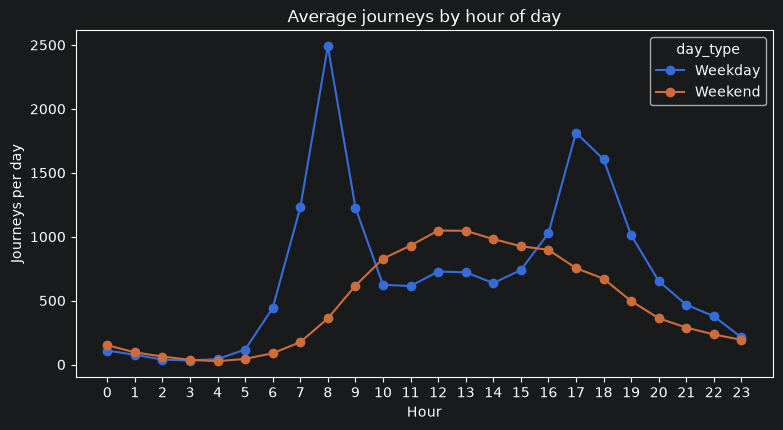

In [2]:
hourly = db.query("""
    SELECT EXTRACT(HOUR FROM start_time)::int AS hour,
           CASE WHEN EXTRACT(ISODOW FROM start_time) <= 5
                THEN 'Weekday' ELSE 'Weekend' END AS day_type,
           (COUNT(*)::float / COUNT(DISTINCT start_time::date)) AS avg_journeys
    FROM clean.journeys
    GROUP BY 1, 2
    ORDER BY 1
""")

ax = hourly.pivot(index="hour", columns="day_type", values="avg_journeys").plot(
    marker="o", figsize=(9, 4.5))
ax.set(title="Average journeys by hour of day", xlabel="Hour", ylabel="Journeys per day")
ax.set_xticks(range(0, 24))
plt.savefig(FIG_DIR / "hourly_demand.png", dpi=150, bbox_inches="tight")
plt.show()

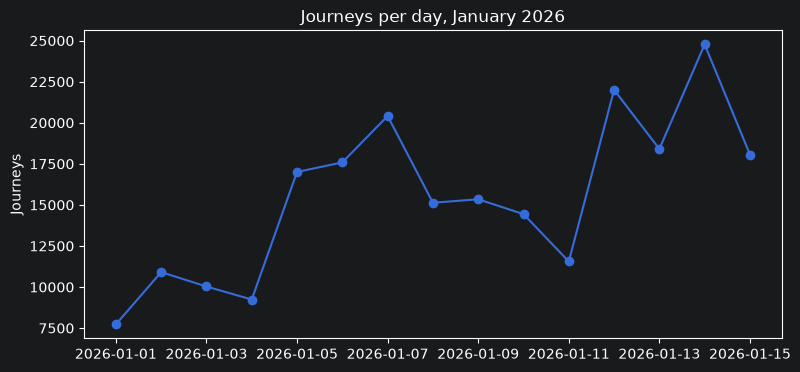

In [3]:
daily = db.query("""
    SELECT start_time::date AS day, COUNT(*) AS journeys
    FROM clean.journeys
    GROUP BY 1
    ORDER BY 1
""")

ax = daily.plot(x="day", y="journeys", marker="o", legend=False, figsize=(9, 4))
ax.set(title="Journeys per day, January 2026", xlabel="", ylabel="Journeys")
plt.savefig(FIG_DIR / "daily_journeys.png", dpi=150, bbox_inches="tight")
plt.show()

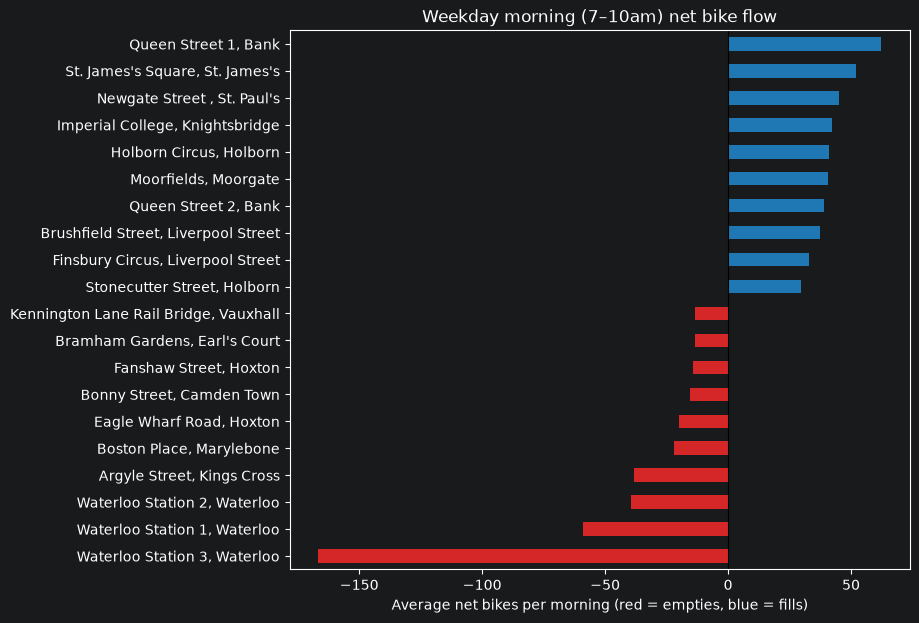

In [4]:
flow = db.query("""
    SELECT station_name, avg_net_inflow::float AS net
    FROM clean.morning_net_flow
    ORDER BY net
""")

extremes = pd.concat([flow.head(10), flow.tail(10)])
colours = ["tab:red" if v < 0 else "tab:blue" for v in extremes["net"]]

ax = extremes.plot.barh(x="station_name", y="net", color=colours,
                        legend=False, figsize=(8, 7))
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Weekday morning (7–10am) net bike flow",
       xlabel="Average net bikes per morning (red = empties, blue = fills)", ylabel="")
plt.savefig(FIG_DIR / "morning_net_flow.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
from rebalance import RebalancingProblem

flow = db.query("""
    SELECT f.station_id, f.station_name, f.avg_net_inflow::float AS net, l.lat, l.lon
    FROM clean.morning_net_flow f
    JOIN clean.station_locations l USING (station_id)
""")

problem = RebalancingProblem(flow, min_imbalance=2)
print(len(problem.supply), "surplus stations,", len(problem.demand), "short stations")
print(problem.total, "bikes to move")

optimal = problem.solve_optimal()
greedy = problem.solve_greedy()

opt_km = optimal["bike_km"].sum()
greedy_km = greedy["bike_km"].sum()
print(f"Greedy:  {greedy_km:,.0f} bike-km")
print(f"Optimal: {opt_km:,.0f} bike-km ({1 - opt_km / greedy_km:.1%} less)")

optimal.sort_values("bikes", ascending=False).head(10)

254 surplus stations, 415 short stations
2439 bikes to move
Solver status: Optimal
Greedy:  5,900 bike-km
Optimal: 4,935 bike-km (16.4% less)


,from_id,to_id,bikes,from_name,to_name,km,bike_km
166,001074,001072,37,"Newgate Street , St. Paul's","Waterloo Station 3, Waterloo",1.604481,59.365811
142,001061,001072,30,"Stonecutter Street, Holborn","Waterloo Station 3, Waterloo",1.434958,43.048737
576,300096,001072,17,"Tallis Street, Temple","Waterloo Station 3, Waterloo",0.977139,16.611362
586,300220,001072,16,"Farringdon Street, Holborn","Waterloo Station 3, Waterloo",1.544281,24.708493
134,001052,001035,15,"Soho Square , Soho","Boston Place, Marylebone",2.210285,33.154280
488,200094,001072,15,"St. Bride Street, Holborn","Waterloo Station 3, Waterloo",1.336892,20.053384
327,002677,001183,14,"Natural History Museum, South Kensington","Bramham Gardens, Earl's Court",0.989027,13.846383
544,200212,001072,13,"Blackfriars Station, St. Paul's","Waterloo Station 3, Waterloo",1.129078,14.678014
467,200044,001072,13,"New Fetter Lane, Holborn","Waterloo Station 3, Waterloo",1.552873,20.187352
371,003449,001072,12,"Breams Buildings, Holborn","Waterloo Station 3, Waterloo",1.352512,16.230146


In [6]:
print(optimal["bikes"].sum(), greedy["bikes"].sum(), problem.total)

2439 2439 2439


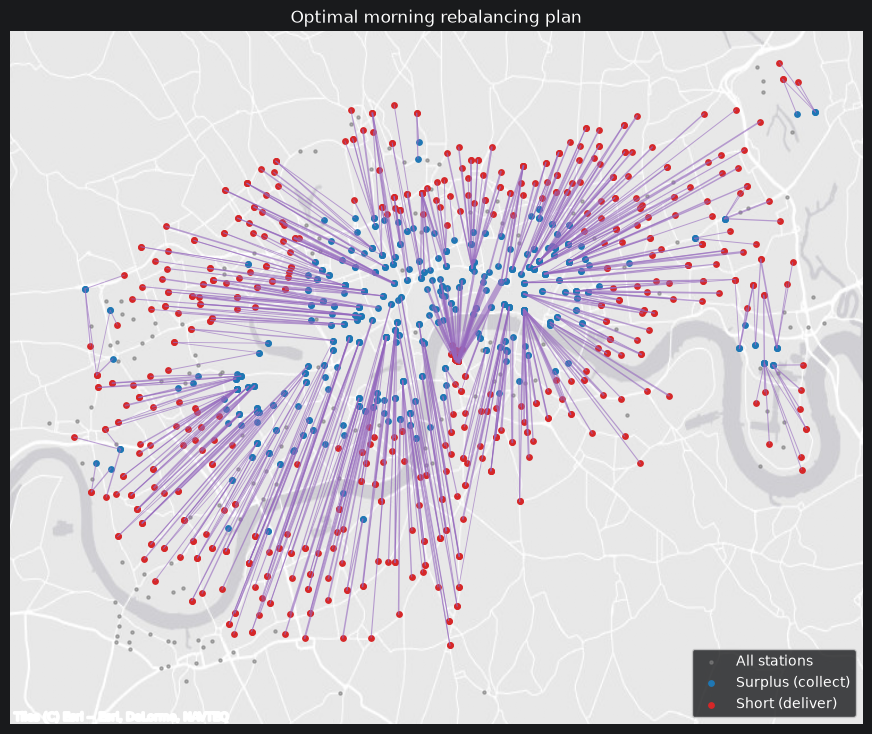

In [11]:
import contextily as ctx
import numpy as np

def to_web_mercator(lat, lon):
    R = 6378137
    x = np.radians(lon) * R
    y = np.log(np.tan(np.pi / 4 + np.radians(lat) / 2)) * R
    return x, y

coords = flow.set_index("station_id")[["lat", "lon"]]
plan = (optimal
        .join(coords, on="from_id")
        .join(coords, on="to_id", lsuffix="_from", rsuffix="_to"))

all_x, all_y = to_web_mercator(flow["lat"], flow["lon"])
plan["x_from"], plan["y_from"] = to_web_mercator(plan["lat_from"], plan["lon_from"])
plan["x_to"], plan["y_to"] = to_web_mercator(plan["lat_to"], plan["lon_to"])

fig, ax = plt.subplots(figsize=(11, 9))
ax.scatter(all_x, all_y, s=5, color="grey", alpha=0.6, label="All stations")
for r in plan.itertuples():
    ax.plot([r.x_from, r.x_to], [r.y_from, r.y_to],
            color="tab:purple", alpha=0.6, linewidth=0.5 + r.bikes / 10)
ax.scatter(plan["x_from"], plan["y_from"], s=15, color="tab:blue", label="Surplus (collect)")
ax.scatter(plan["x_to"], plan["y_to"], s=15, color="tab:red", label="Short (deliver)")

ctx.set_cache_dir("/tmp/contextily_cache")
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
ax.set_axis_off()
ax.set_title("Optimal morning rebalancing plan")
ax.legend(loc="lower right")
plt.savefig(FIG_DIR / "rebalancing_plan.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
optimal.to_sql("rebalancing_plan", db.engine, schema="clean",
               if_exists="replace", index=False)

615

Chosen alpha: 0.45
Ridge MAE:    141 journeys/hour
Baseline MAE: 196 journeys/hour


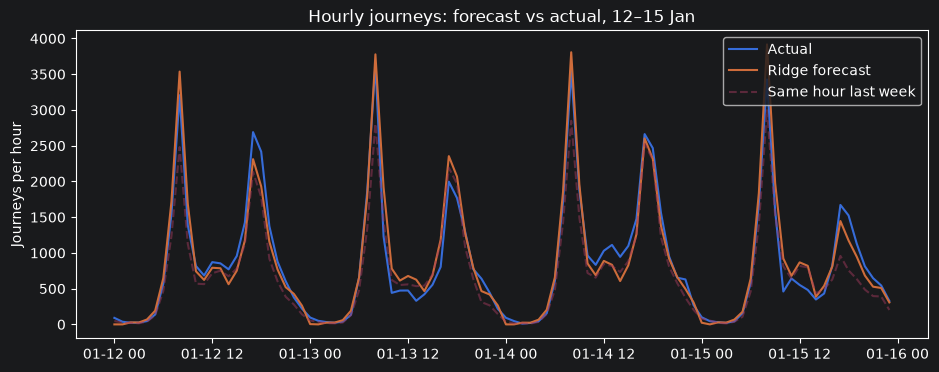

In [13]:
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error

hourly = db.query("""
    SELECT date_trunc('hour', start_time) AS hour, COUNT(*) AS journeys
    FROM clean.journeys
    GROUP BY 1
""").set_index("hour")

all_hours = pd.date_range(hourly.index.min(), hourly.index.max(), freq="h")
df = hourly.reindex(all_hours, fill_value=0).rename_axis("hour").reset_index()

days_off = ["2026-01-01", "2026-01-02"]
is_off = (df["hour"].dt.dayofweek >= 5) | df["hour"].dt.strftime("%Y-%m-%d").isin(days_off)
df["hour_x_day"] = df["hour"].dt.hour.astype(str) + "_" + np.where(is_off, "off", "work")
df["lag_1w"] = df["journeys"].shift(24 * 7)       # same hour one week earlier
df = df.dropna()

train = df[df["hour"] < "2026-01-12"]
test = df[df["hour"] >= "2026-01-12"]
features = ["hour_x_day", "lag_1w"]

model = make_pipeline(
    ColumnTransformer([
        ("hour", OneHotEncoder(handle_unknown="ignore"), ["hour_x_day"]),
        ("lag", StandardScaler(), ["lag_1w"]),
    ]),
    RidgeCV(alphas=np.logspace(-2, 4, 30)),
)
model.fit(train[features], train["journeys"])
pred = model.predict(test[features]).clip(0)

print(f"Chosen alpha: {model[-1].alpha_:.2f}")
print(f"Ridge MAE:    {mean_absolute_error(test['journeys'], pred):.0f} journeys/hour")
print(f"Baseline MAE: {mean_absolute_error(test['journeys'], test['lag_1w']):.0f} journeys/hour")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(test["hour"], test["journeys"], label="Actual")
ax.plot(test["hour"], pred, label="Ridge forecast")
ax.plot(test["hour"], test["lag_1w"], label="Same hour last week", alpha=0.5, linestyle="--")
ax.set(title="Hourly journeys: forecast vs actual, 12–15 Jan", ylabel="Journeys per hour")
ax.legend()
plt.savefig(FIG_DIR / "ridge_forecast.png", dpi=150, bbox_inches="tight")
plt.show()